# PhysioNet 2017 — deteção binária de anomalias

**Normal (0): N. Anomalia (1): A/O no PhysioNet e S/V no Icentia. ~ e Q são excluídos** de fit, holdout local, dev e das estatísticas de normalização. Todas as redes têm duas saídas; os clássicos são ajustados a labels 0/1. Não é uma redução posterior das previsões de um modelo treinado com quatro classes.

Mantemos os IDs e splits shared_smoke_v2, filtrando apenas os exemplos não elegíveis: PhysioNet **354 fit / 90 holdout local / 59 dev**; Icentia **792 fit / 203 holdout local / 94 dev**. O holdout local é exclusivo do FL. Test não é carregado. O protocolo ativo é `binary_smoke_v3`; resultados anteriores estão arquivados.

Comparação dos 14 modelos usando sinal + features. **Ranking pelo PR-AUC da classe anomalia**, ROC-AUC positivo como desempate. F1, precision, recall, miss rate e FAR principais referem-se à classe anomalia. Métricas macro são apenas auxiliares, não definem o ranking. Decisão por argmax: em empate prevê normal.

Três épocas supervisionadas por rede; autoencoder com duas épocas extra. CNN otimizada usa lr fixo 0,0003, restantes 0,001. Arquiteturas reduzidas, GRU com pooling até 500 passos. Clássicos usam a mesma projeção pública de 32 dimensões + features normalizadas em fit do FL; SVM central é RBF e FL linear, Log Reg usa sklearn aqui e AdamW no FL. Estes fatores limitam atribuir diferenças só à agregação.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
PROJECT_ROOT=Path.cwd().resolve()
while not (PROJECT_ROOT/'requirements.txt').is_file() and PROJECT_ROOT!=PROJECT_ROOT.parent:
    PROJECT_ROOT=PROJECT_ROOT.parent
sys.path.insert(0,str(PROJECT_ROOT/'support'/'model_tests'))
from shared_smoke import load_dataset,run_model,sample_percentages,MODELS,SEED
DATASET='physionet2017'
train,dev,config,clients=load_dataset(DATASET)
assert set(np.unique(train['y']))=={0,1} and config['task']=='binary'
percentages=pd.DataFrame(sample_percentages(DATASET,clients))
class_names=['Normal','Anomalia']
display(percentages.round(6))
display(pd.DataFrame({'Classe':class_names,'Fit':np.bincount(train['y'],minlength=2),'Dev':np.bincount(dev['y'],minlength=2)}))
print('Fit:',len(train['y']),'Dev:',len(dev['y']),'Test: 0 exemplos')
results=[]


dataset,split,clients,available,selected,fit_or_dev,local_holdout,excluded_selected,selected_percent,used_percent
physionet2017,train,6,6398,444,354,90,36,6.939669,5.532979
physionet2017,dev,1,1065,59,59,0,5,5.539906,5.539906


Classe,Fit,Dev
Normal,204,34
Anomalia,150,25


Fit: 354 Dev: 59 Test: 0 exemplos


In [2]:
results.append(run_model(DATASET,'LogReg',train,dev,config))

Log Reg: PR-AUC=0.5054; 0.0s


In [3]:
results.append(run_model(DATASET,'SVM',train,dev,config))

SVM: PR-AUC=0.4442; 0.0s


In [4]:
results.append(run_model(DATASET,'KNN',train,dev,config))

KNN: PR-AUC=0.4557; 0.1s


In [5]:
results.append(run_model(DATASET,'RandomForest',train,dev,config))

Random Forest: PR-AUC=0.4743; 0.3s


In [6]:
results.append(run_model(DATASET,'CNN1D',train,dev,config))

CNN 1D: PR-AUC=0.6790; 1.7s


In [7]:
results.append(run_model(DATASET,'CNN1D_Optimized',train,dev,config))

CNN 1D otimizada: PR-AUC=0.6597; 1.0s


In [8]:
results.append(run_model(DATASET,'CNN_BiLSTM',train,dev,config))

CNN 1D + BiLSTM: PR-AUC=0.7747; 2.2s


In [9]:
results.append(run_model(DATASET,'CNN_BiLSTM_Attention',train,dev,config))

CNN 1D + BiLSTM + Attention: PR-AUC=0.7346; 2.2s


In [10]:
results.append(run_model(DATASET,'CNN_BiLSTM_CBAM',train,dev,config))

CNN 1D + BiLSTM + CBAM: PR-AUC=0.6758; 2.3s


In [11]:
results.append(run_model(DATASET,'Autoencoder_CNN_GradCAM',train,dev,config))

Autoencoder + CNN 1D + Grad-CAM: PR-AUC=0.6236; 0.9s


In [12]:
results.append(run_model(DATASET,'ResNet34',train,dev,config))

ResNet-34 1D: PR-AUC=0.6313; 16.5s


In [13]:
results.append(run_model(DATASET,'MobileNetV2',train,dev,config))

MobileNetV2 1D: PR-AUC=0.5772; 78.5s


In [14]:
results.append(run_model(DATASET,'GRU5',train,dev,config))

GRU de cinco camadas: PR-AUC=0.5602; 40.9s


In [15]:
results.append(run_model(DATASET,'GRU_Simple',train,dev,config))

GRU simplificada: PR-AUC=0.5317; 8.0s


## Comparação — PR-AUC da anomalia em dev

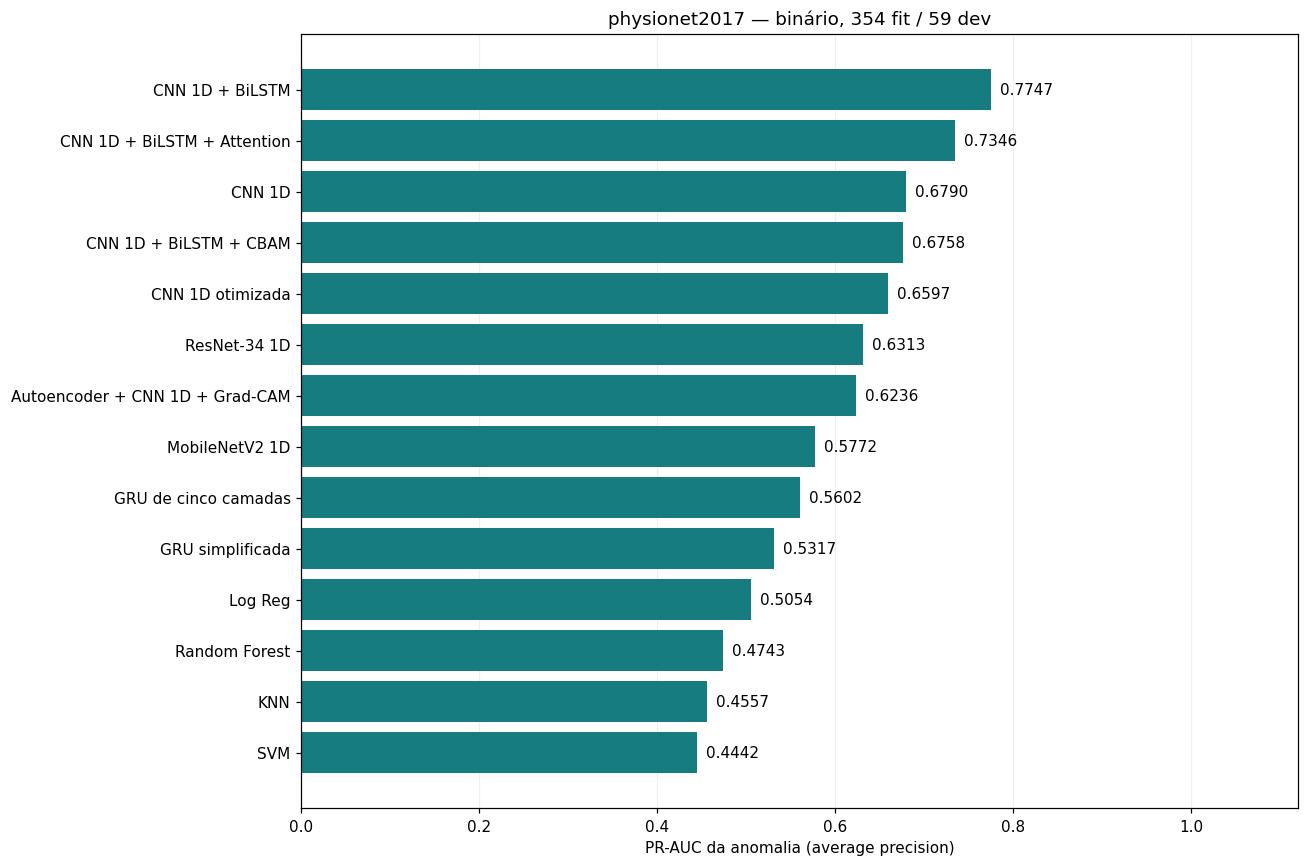

In [16]:
PR='anomaly_pr_auc_ap'
comparison=pd.DataFrame(results).sort_values([PR,'anomaly_roc_auc'],ascending=False).reset_index(drop=True)
assert len(comparison)==comparison.model.nunique()==14
fig,ax=plt.subplots(figsize=(12,8))
bars=ax.barh(comparison.model,comparison[PR],color='#167c80')
for bar,value in zip(bars,comparison[PR]):ax.text(value+.01,bar.get_y()+bar.get_height()/2,f'{value:.4f}',va='center')
ax.invert_yaxis();ax.set_xlim(0,1.12);ax.set_xlabel('PR-AUC da anomalia (average precision)')
ax.set_title(f"{DATASET} — binário, {len(train['y'])} fit / {len(dev['y'])} dev")
ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True);fig.tight_layout();plt.show();plt.close(fig)


## Tabela final — métricas binárias da classe anomalia

In [17]:
columns=['model','accuracy','f1','precision','recall','roc_auc',PR,'miss_rate','far','fit_seconds']
payload={'kind':'ecg_validation_results','dataset':DATASET,'protocol':{'id':'binary_smoke_v3','task':'binary','positive_class':1,'train_examples':len(train['y']),'dev_examples':len(dev['y']),'test_used':False,'seed':SEED,'train_ids':train['sample_ids'].tolist(),'dev_ids':dev['sample_ids'].tolist()},'sampling':percentages.to_dict('records'),'rows':json.loads(comparison.to_json(orient='records',double_precision=15))}
display({'text/html':comparison[columns].round(4).to_html(index=False),'text/plain':comparison[columns].round(4).to_string(index=False),'application/json':payload},raw=True)
best=comparison.iloc[0]
display(Markdown(f"**Candidato exploratório: {best['model']}**, AP da anomalia {best[PR]:.4f}; ROC-AUC {best['roc_auc']:.4f}. F1 e recall positivos referem-se à anomalia. Dev é pequeno e enriquecido; os resultados não são uma avaliação final."))


model,accuracy,f1,precision,recall,roc_auc,anomaly_pr_auc_ap,miss_rate,far,fit_seconds
CNN 1D + BiLSTM,0.7288,0.6000,0.8000,0.48,0.8176,0.7747,0.52,0.0882,2.1789
CNN 1D + BiLSTM + Attention,0.6610,0.4737,0.6923,0.36,0.7729,0.7346,0.64,0.1176,2.2186
CNN 1D,0.7119,0.6383,0.6818,0.60,0.7612,0.6790,0.40,0.2059,1.6724
CNN 1D + BiLSTM + CBAM,0.6441,0.6038,0.5714,0.64,0.7318,0.6758,0.36,0.3529,2.2880
CNN 1D otimizada,0.6271,0.3889,0.6364,0.28,0.7153,0.6597,0.72,0.1176,1.0424
ResNet-34 1D,0.5763,0.0741,0.5000,0.04,0.6882,0.6313,0.96,0.0294,16.5356
Autoencoder + CNN 1D + Grad-CAM,0.6780,0.6275,0.6154,0.64,0.7118,0.6236,0.36,0.2941,0.8653
MobileNetV2 1D,0.6102,0.4390,0.5625,0.36,0.5529,0.5772,0.64,0.2059,78.4891
GRU de cinco camadas,0.4746,0.5634,0.4348,0.80,0.6447,0.5602,0.20,0.7647,40.8980
GRU simplificada,0.5254,0.5333,0.4571,0.64,0.5694,0.5317,0.36,0.5588,8.0488


**Candidato exploratório: CNN 1D + BiLSTM**, AP da anomalia 0.7747; ROC-AUC 0.8176. F1 e recall positivos referem-se à anomalia. Dev é pequeno e enriquecido; os resultados não são uma avaliação final.

## Miss rate e FAR

Miss rate = FN/(TP+FN) = 1 − recall da anomalia. FAR = FP/(FP+TN). Menor é melhor; FAR não é alarmes por hora. AUC/AP sem positivos e negativos são indefinidas.

In [18]:
assert np.allclose(comparison.miss_rate,1-comparison.recall,equal_nan=True)
display(comparison[['model','recall','miss_rate','far',PR]].rename(columns={'model':'Modelo','recall':'Recall da anomalia','miss_rate':'Miss rate ↓','far':'FAR ↓',PR:'PR-AUC da anomalia'}).round(4))


Modelo,Recall da anomalia,Miss rate ↓,FAR ↓,PR-AUC da anomalia
CNN 1D + BiLSTM,0.48,0.52,0.0882,0.7747
CNN 1D + BiLSTM + Attention,0.36,0.64,0.1176,0.7346
CNN 1D,0.60,0.40,0.2059,0.6790
CNN 1D + BiLSTM + CBAM,0.64,0.36,0.3529,0.6758
CNN 1D otimizada,0.28,0.72,0.1176,0.6597
ResNet-34 1D,0.04,0.96,0.0294,0.6313
Autoencoder + CNN 1D + Grad-CAM,0.64,0.36,0.2941,0.6236
MobileNetV2 1D,0.36,0.64,0.2059,0.5772
GRU de cinco camadas,0.80,0.20,0.7647,0.5602
GRU simplificada,0.64,0.36,0.5588,0.5317


## Matrizes de confusão — exclusivamente dev

Grelha dos 14 modelos e PNG individual por modelo. Linhas: classe real; colunas: classe prevista. Contagens absolutas. Normal = 0; anomalia = 1.

O falso negativo é a célula **real Anomalia / prevista Normal**; o miss rate divide essa contagem pelo total da linha Anomalia.

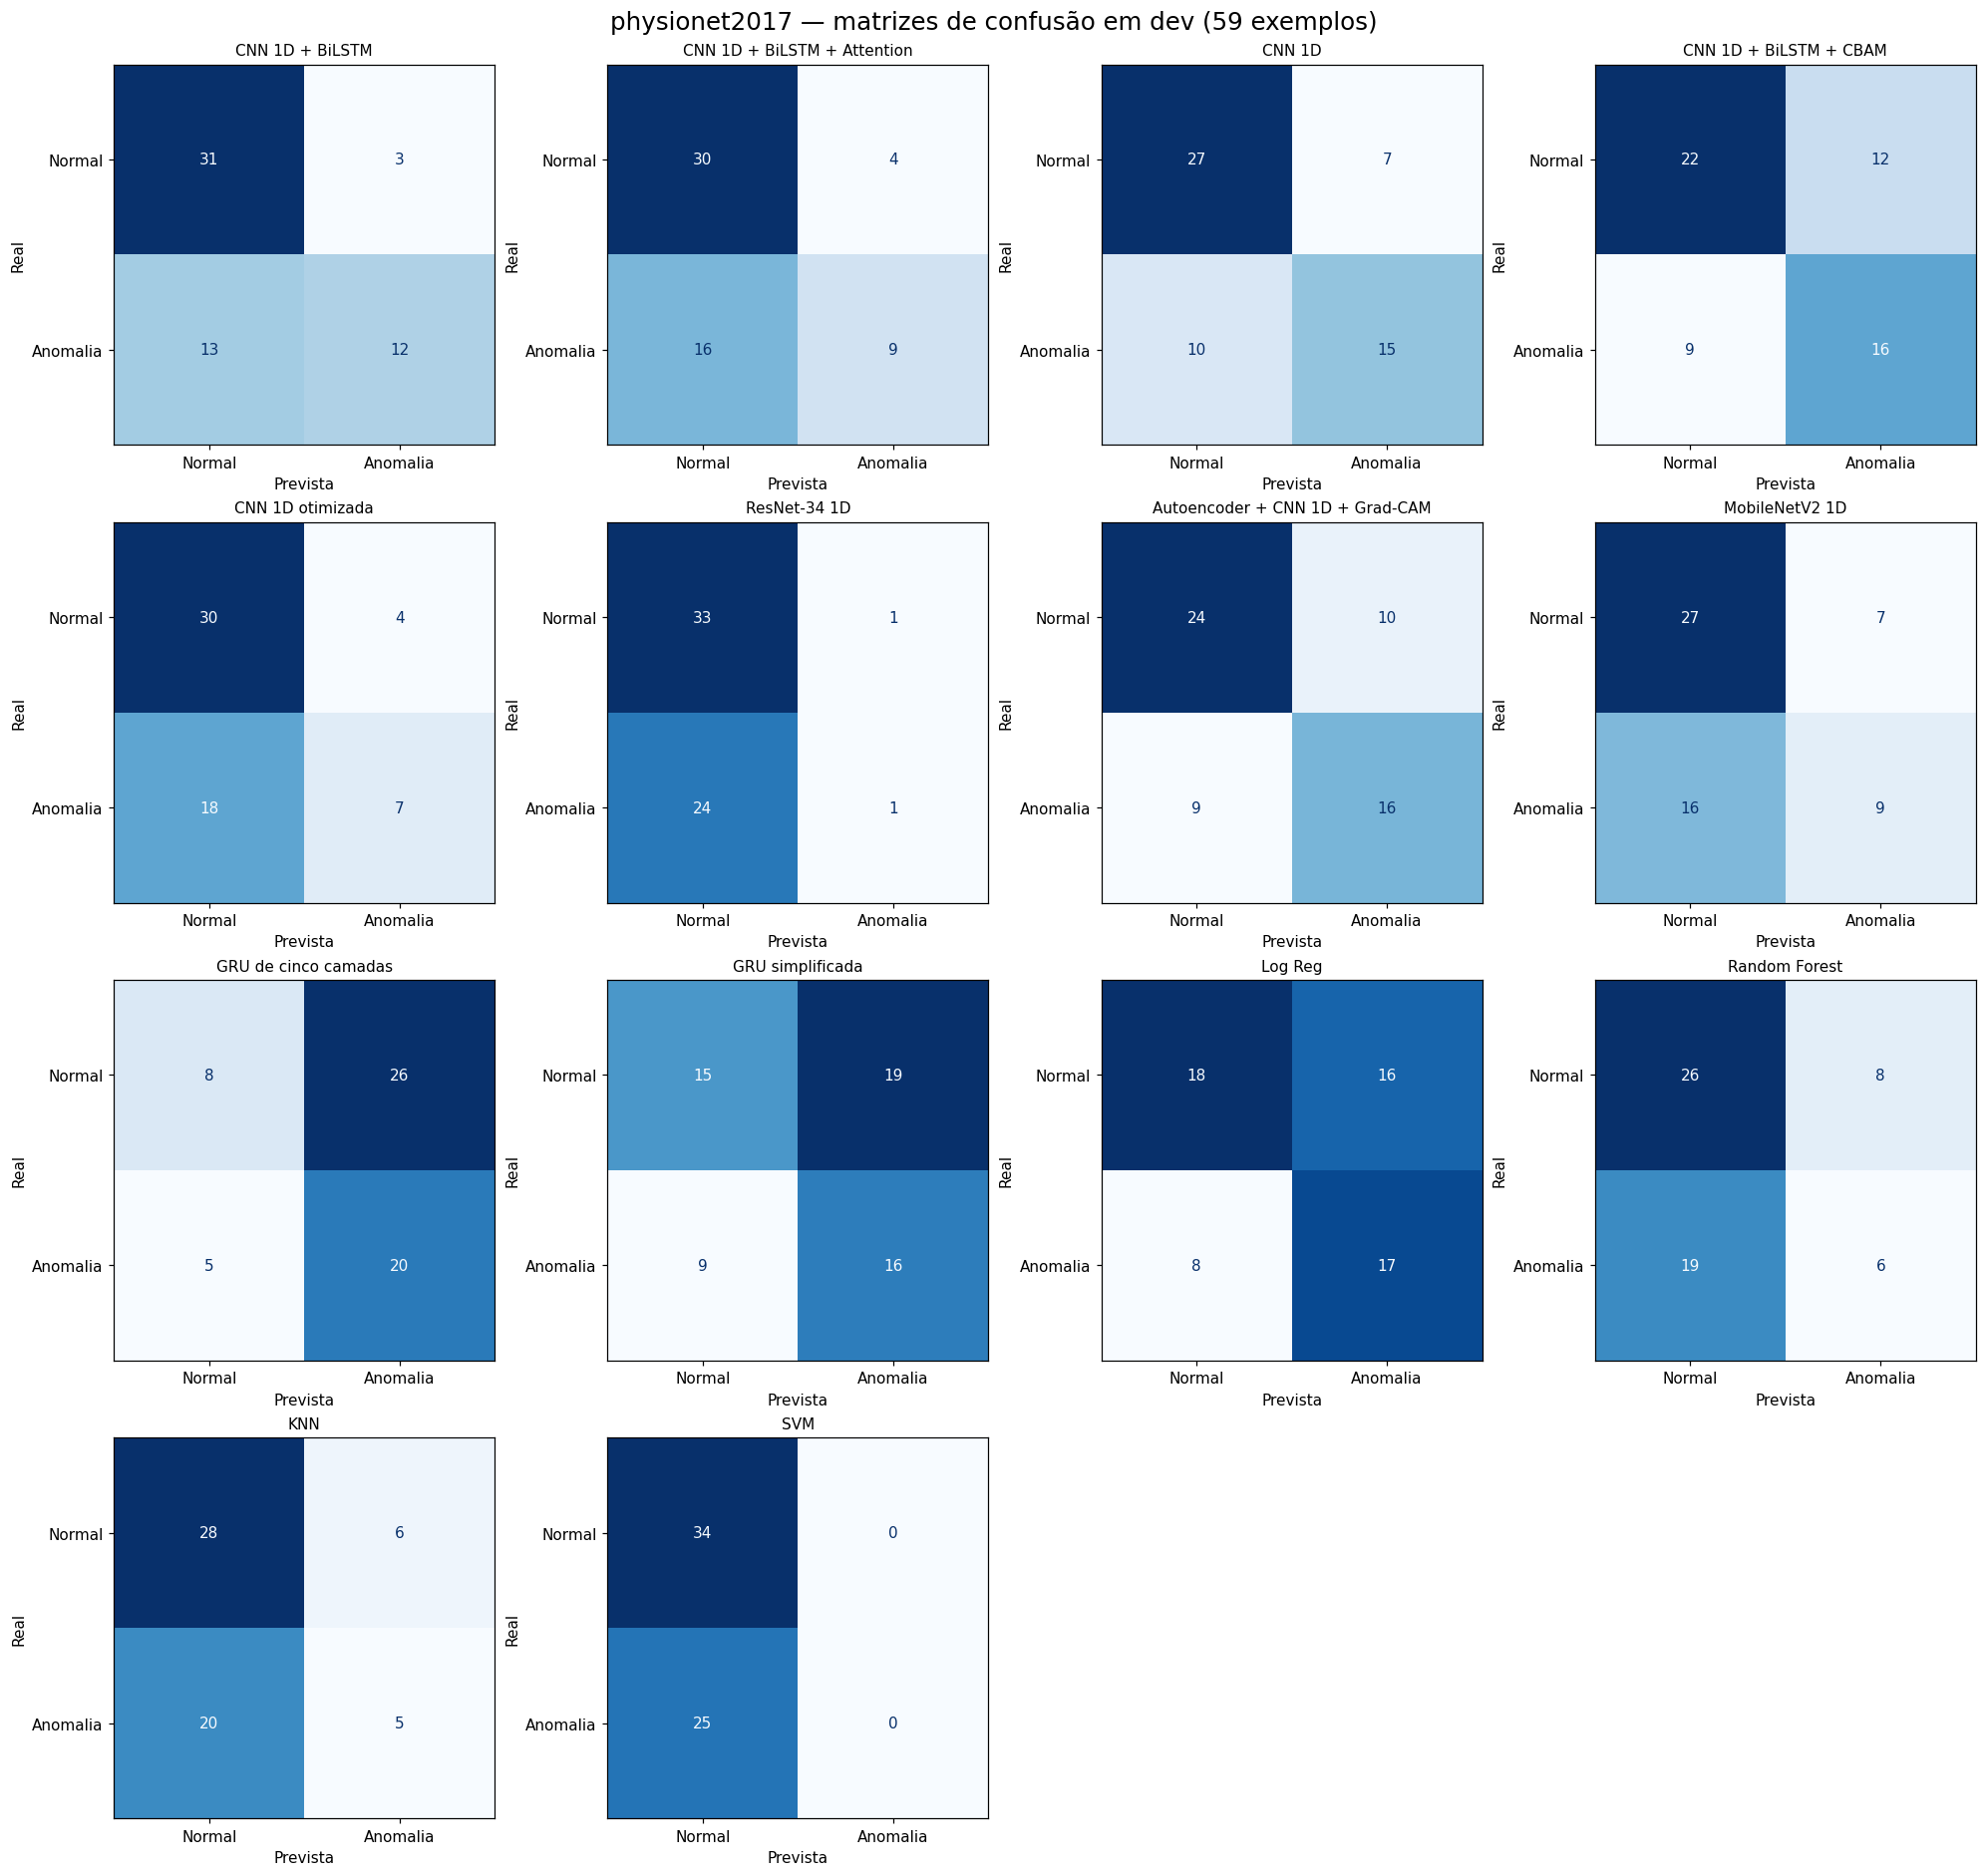

PNG conjunto: /Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/Tests/artifacts/model_smoke_tests/binary_smoke_v3/physionet2017/confusion_matrices_dev.png
PNGs individuais: /Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/Tests/artifacts/model_smoke_tests/binary_smoke_v3/physionet2017/confusion_matrices/dev


In [19]:
from shared_smoke import save_confusion_matrices
fig,individual_folder,joint_png=save_confusion_matrices(DATASET,dev,comparison)
plt.show();plt.close(fig)
print('PNG conjunto:',joint_png)
print('PNGs individuais:',individual_folder)


## Grad-CAM do autoencoder + CNN

Primeiro exemplo dev de cada classe, sem selecionar por acerto. Explica a previsão do modelo binário já treinado; não ajusta pesos.

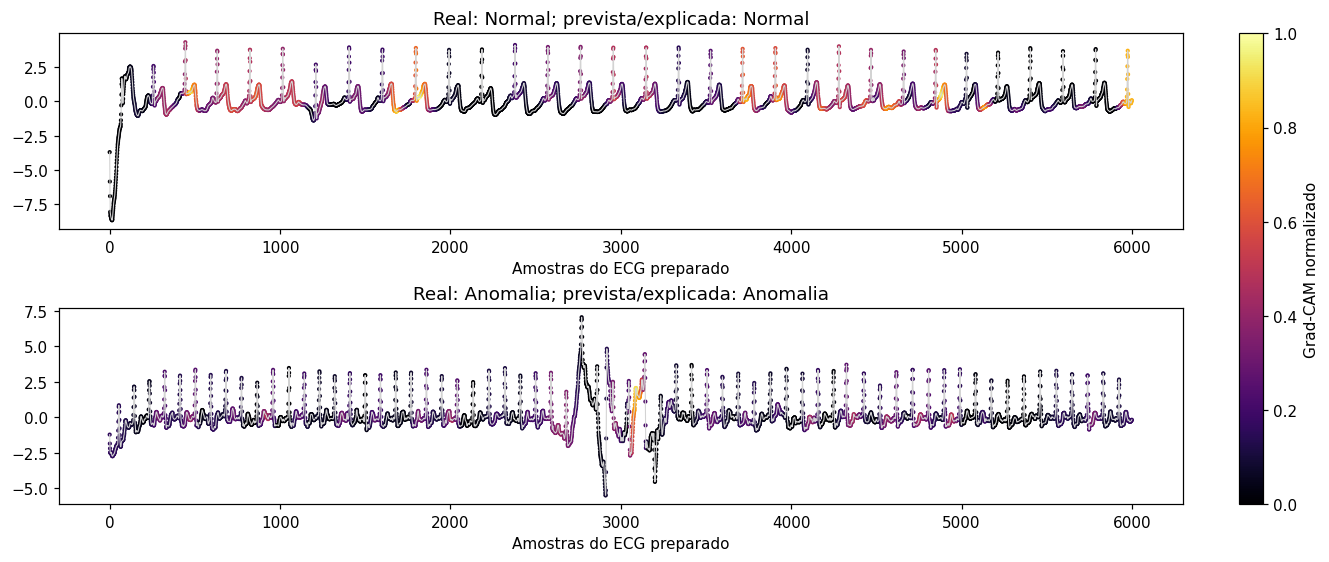

In [20]:
from shared_smoke import save_gradcam
heatmaps,indices,predictions=save_gradcam(DATASET,dev,config)
fig,axes=plt.subplots(len(indices),1,figsize=(12,5),constrained_layout=True)
for ax,index,heat,predicted in zip(np.atleast_1d(axes),indices,heatmaps,predictions):
    length=int(dev['valid_lengths'][index])
    ax.plot(dev['X'][index,:length],color='lightgray',linewidth=.7)
    scatter=ax.scatter(np.arange(length),dev['X'][index,:length],c=heat[:length],cmap='inferno',s=3,vmin=0,vmax=1)
    ax.set_title(f"Real: {class_names[dev['y'][index]]}; prevista/explicada: {class_names[predicted]}")
    ax.set_xlabel('Amostras do ECG preparado')
fig.colorbar(scatter,ax=axes,label='Grad-CAM normalizado');plt.show();plt.close(fig)


## Percentagens efetivamente utilizadas

Denominador: tamanho do split preparado original, antes de excluir ~ / Q. `fit_or_dev` é o treino efetivo ou a avaliação dev. `local_holdout` é reservado ao FL, separado de fit. `excluded_selected` mostra os exemplos da seleção antiga removidos por ~ / Q. Test: zero exemplos.

In [21]:
display(percentages.round(6))

dataset,split,clients,available,selected,fit_or_dev,local_holdout,excluded_selected,selected_percent,used_percent
physionet2017,train,6,6398,444,354,90,36,6.939669,5.532979
physionet2017,dev,1,1065,59,59,0,5,5.539906,5.539906
